# AnalystLab Africa – Week 2 Assignment
## Data Preprocessing & Feature Engineering for Machine Learning

**Programme:** Machine Learning Internship  
**Project:** ShopSmart Retail Dataset – Preprocessing Pipeline  
**Author:** Junior ML Engineer (AnalystLab Africa)  
**Date:** October 2026

---

### Business Scenario
As a Junior Machine Learning Engineer at AnalystLab Africa, the goal is to transform the raw ShopSmart multi-table retail dataset into a clean, machine-learning-ready dataset. Real-world issues (missing values, inconsistent formats, categorical variables, outliers, irrelevant features) are addressed systematically.

### Business Objective
Prepare a customer-level feature set that can support downstream models such as:
- Customer segment classification / upgrade prediction
- Customer lifetime value (CLV) estimation
- Churn risk scoring
- Next-purchase propensity

### Dataset
ShopSmart retail data (Customers, Orders, Products, Stores, Returns).

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import (
    LabelEncoder, OneHotEncoder, OrdinalEncoder,
    StandardScaler, MinMaxScaler, RobustScaler
)
from sklearn.feature_selection import VarianceThreshold
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Part 1 – Data Inspection
### 2.1 Load the Datasets

In [2]:
# Paths (adjust if running from a different location)
DATA_DIR = '../data/'   # relative to notebook location after extraction

customers   = pd.read_csv(DATA_DIR + 'ALA_ShopSmart_Customers.csv')
orders      = pd.read_csv(DATA_DIR + 'ShopSmart_Orders.csv')
products    = pd.read_csv(DATA_DIR + 'ShopSmart_Products.csv')
stores      = pd.read_csv(DATA_DIR + 'ShopSmart_Stores.csv')
returns     = pd.read_csv(DATA_DIR + 'ShopSmart_Returns.csv')

print("Datasets loaded.")
print(f"Customers : {customers.shape}")
print(f"Orders    : {orders.shape}")
print(f"Products  : {products.shape}")
print(f"Stores    : {stores.shape}")
print(f"Returns   : {returns.shape}")

Datasets loaded.
Customers : (5000, 11)
Orders    : (50000, 12)
Products  : (500, 7)
Stores    : (25, 6)
Returns   : (2500, 5)


### 2.2 Display First 10 Rows (Customers & Orders)

In [3]:
print("=== Customers (first 10) ===")
display(customers.head(10))

print("\n=== Orders (first 10) ===")
display(orders.head(10))

=== Customers (first 10) ===


,Customer_ID,First_Name,Last_Name,Gender,Age,Email,Phone,City,State,Registration_Date,Customer_Segment
0,CUST00001,Michelle,Russell,Male,65,elizabethfox@example.net,(701)981-5738x907,Abuja,Abuja,10/9/2023,Bronze
1,CUST00002,Sarah,Yu,Male,65,tfleming@example.com,6314323702,Kano,Kano,4/15/2023,Gold
2,CUST00003,Elizabeth,Adkins,Male,55,petertaylor@example.com,001-454-212-5805x0434,Asaba,Delta,3/8/2024,Bronze
3,CUST00004,Nicholas,Marshall,Male,31,kbean@example.net,001-513-728-5958x132,Lagos,Lagos,8/27/2023,Gold
4,CUST00005,Melinda,Patton,Male,53,mikaylajames@example.com,652-819-2186,Awka,Anambra,7/23/2023,Gold
5,CUST00006,Mary,Burnett,Female,32,sheppardkatie@example.org,(995)816-7832,Asaba,Delta,4/4/2024,Gold
6,CUST00007,Troy,Brewer,Male,66,rwilliams@example.com,001-583-806-8069,Port Harcourt,Rivers,4/5/2025,Bronze
7,CUST00008,Gabriel,Herring,Female,35,chelseamoreno@example.net,793.905.1919,Enugu,Enugu,6/9/2023,Bronze
8,CUST00009,James,Petty,Male,23,harold69@example.org,227.333.2706x1247,Kaduna,Kaduna,1/25/2024,Bronze
9,CUST00010,Mark,Smith,Female,56,yedwards@example.net,001-421-868-1363,Kaduna,Kaduna,9/28/2023,Bronze



=== Orders (first 10) ===


,Order_ID,Customer_ID,Product_ID,Store_ID,Order_Date,Quantity,Unit_Price,Discount,Shipping_Cost,Payment_Method,Sales_Channel,Order_Status
0,ORD000001,CUST04572,PROD0244,STR005,7/19/2025,1,77989,10,3833,Card,Online,Completed
1,ORD000002,CUST04064,PROD0432,STR010,3/15/2025,3,11240,5,2872,Card,In-Store,Cancelled
2,ORD000003,CUST03435,PROD0052,STR004,10/1/2025,2,23595,20,922,Card,Online,Pending
3,ORD000004,CUST03536,PROD0051,STR023,7/15/2025,4,69922,5,911,Transfer,Online,Completed
4,ORD000005,CUST03676,PROD0356,STR021,3/28/2025,5,53344,0,1740,Card,Online,Cancelled
5,ORD000006,CUST03203,PROD0458,STR014,3/11/2025,3,31991,0,3452,Card,In-Store,Cancelled
6,ORD000007,CUST00082,PROD0174,STR015,9/1/2025,5,5086,20,3064,Card,Online,Completed
7,ORD000008,CUST01119,PROD0171,STR019,1/7/2025,4,32902,0,4279,Card,In-Store,Completed
8,ORD000009,CUST00284,PROD0336,STR015,3/29/2025,2,99649,5,1266,Card,Online,Cancelled
9,ORD000010,CUST00338,PROD0381,STR017,8/30/2025,4,75235,0,3693,Transfer,Online,Completed


### 2.3 Dataset Dimensions & Data Types

In [4]:
print("Customers shape:", customers.shape)
print("Orders shape   :", orders.shape)
print("\n--- Customers dtypes ---")
print(customers.dtypes)
print("\n--- Orders dtypes ---")
print(orders.dtypes)
print("\n--- Products dtypes ---")
print(products.dtypes)

Customers shape: (5000, 11)
Orders shape   : (50000, 12)

--- Customers dtypes ---
Customer_ID          object
First_Name           object
Last_Name            object
Gender               object
Age                   int64
Email                object
Phone                object
City                 object
State                object
Registration_Date    object
Customer_Segment     object
dtype: object

--- Orders dtypes ---
Order_ID          object
Customer_ID       object
Product_ID        object
Store_ID          object
Order_Date        object
Quantity           int64
Unit_Price         int64
Discount           int64
Shipping_Cost      int64
Payment_Method    object
Sales_Channel     object
Order_Status      object
dtype: object

--- Products dtypes ---
Product_ID        object
Product_Name      object
Category          object
Sub_Category      object
Brand             object
Cost_Price         int64
Selling_Price    float64
dtype: object


### 2.4 Identify Missing Values

In [5]:
print("=== Missing values – Customers ===")
print(customers.isnull().sum())
print("\n=== Missing values – Orders ===")
print(orders.isnull().sum())
print("\n=== Missing values – Products ===")
print(products.isnull().sum())
print("\n=== Missing values – Returns ===")
print(returns.isnull().sum())
print("\n=== Missing values – Stores ===")
print(stores.isnull().sum())

=== Missing values – Customers ===
Customer_ID          0
First_Name           0
Last_Name            0
Gender               0
Age                  0
Email                0
Phone                0
City                 0
State                0
Registration_Date    0
Customer_Segment     0
dtype: int64

=== Missing values – Orders ===
Order_ID          0
Customer_ID       0
Product_ID        0
Store_ID          0
Order_Date        0
Quantity          0
Unit_Price        0
Discount          0
Shipping_Cost     0
Payment_Method    0
Sales_Channel     0
Order_Status      0
dtype: int64

=== Missing values – Products ===
Product_ID       0
Product_Name     0
Category         0
Sub_Category     0
Brand            0
Cost_Price       0
Selling_Price    0
dtype: int64

=== Missing values – Returns ===
Return_ID        0
Order_ID         0
Return_Date      0
Return_Reason    0
Refund_Amount    0
dtype: int64

=== Missing values – Stores ===
Store_ID        0
Store_Name      0
Region          0
Sta

### 2.5 Identify Duplicate Records

In [6]:
print("Duplicate rows – Customers:", customers.duplicated().sum())
print("Duplicate rows – Orders   :", orders.duplicated().sum())
print("Duplicate Customer_ID     :", customers['Customer_ID'].duplicated().sum())
print("Duplicate Order_ID        :", orders['Order_ID'].duplicated().sum())

Duplicate rows – Customers: 0
Duplicate rows – Orders   : 0
Duplicate Customer_ID     : 0
Duplicate Order_ID        : 0


### 2.6 Descriptive Statistics

In [7]:
print("=== Customers – Numeric ===")
display(customers.describe())

print("\n=== Orders – Numeric ===")
display(orders.describe())

print("\n=== Categorical value counts (key columns) ===")
print("\nGender:\n", customers['Gender'].value_counts())
print("\nCustomer_Segment:\n", customers['Customer_Segment'].value_counts())
print("\nOrder_Status:\n", orders['Order_Status'].value_counts())
print("\nPayment_Method:\n", orders['Payment_Method'].value_counts())
print("\nSales_Channel:\n", orders['Sales_Channel'].value_counts())
print("\nProduct Category:\n", products['Category'].value_counts())

=== Customers – Numeric ===


,Age
count,5000.000000
mean,44.150800
std,15.382555
min,18.000000
25%,30.000000
50%,44.000000
75%,58.000000
max,70.000000



=== Orders – Numeric ===


,Quantity,Unit_Price,Discount,Shipping_Cost
count,50000.00000,50000.000000,50000.000000,50000.000000
mean,2.99846,50428.605120,9.970600,2747.708600
std,1.41480,28582.922652,7.086264,1296.187071
min,1.00000,1003.000000,0.000000,500.000000
25%,2.00000,25648.750000,5.000000,1628.000000
50%,3.00000,50631.000000,10.000000,2751.000000
75%,4.00000,75123.000000,15.000000,3866.000000
max,5.00000,99998.000000,20.000000,5000.000000



=== Categorical value counts (key columns) ===

Gender:
 Gender
Male      2557
Female    2443
Name: count, dtype: int64

Customer_Segment:
 Customer_Segment
Gold      1691
Silver    1674
Bronze    1635
Name: count, dtype: int64

Order_Status:
 Order_Status
Cancelled    16861
Pending      16610
Completed    16529
Name: count, dtype: int64

Payment_Method:
 Payment_Method
Card        16741
Cash        16693
Transfer    16566
Name: count, dtype: int64

Sales_Channel:
 Sales_Channel
In-Store    25018
Online      24982
Name: count, dtype: int64

Product Category:
 Category
Beauty         119
Groceries      102
Electronics     99
Fashion         94
Home            86
Name: count, dtype: int64


## 3. Part 2 – Data Cleaning

### Decisions made
1. **Missing values** – None found in core tables; no imputation required.
2. **Duplicates** – No full-row or primary-key duplicates; no removal needed.
3. **Data types** – Converted date columns to datetime; ensured numeric columns are numeric.
4. **Standardization** – Strip whitespace, standardize string columns.
5. **Inconsistent values** – Gender column shows possible label noise. Kept as-is for encoding; documented for production review.

In [8]:
# Work on copies
cust = customers.copy()
ordr = orders.copy()
prod = products.copy()
stor = stores.copy()
ret  = returns.copy()

# ---- Date conversions ----
cust['Registration_Date'] = pd.to_datetime(cust['Registration_Date'], format='%m/%d/%Y', errors='coerce')
ordr['Order_Date']        = pd.to_datetime(ordr['Order_Date'],        format='%m/%d/%Y', errors='coerce')
ret['Return_Date']        = pd.to_datetime(ret['Return_Date'],        format='%m/%d/%Y', errors='coerce')
stor['Opening_Date']      = pd.to_datetime(stor['Opening_Date'],      format='%m/%d/%Y', errors='coerce')

# ---- Strip whitespace & standardize string IDs ----
for col in ['Customer_ID', 'First_Name', 'Last_Name', 'Gender', 'City', 'State', 'Customer_Segment']:
    if col in cust.columns:
        cust[col] = cust[col].astype(str).str.strip()

for col in ['Order_ID', 'Customer_ID', 'Product_ID', 'Store_ID', 'Payment_Method', 'Sales_Channel', 'Order_Status']:
    if col in ordr.columns:
        ordr[col] = ordr[col].astype(str).str.strip()

# ---- Ensure numeric integrity ----
num_cols_ord = ['Quantity', 'Unit_Price', 'Discount', 'Shipping_Cost']
for c in num_cols_ord:
    ordr[c] = pd.to_numeric(ordr[c], errors='coerce')

cust['Age'] = pd.to_numeric(cust['Age'], errors='coerce')

print("Date conversions and cleaning completed.")
print("Any remaining nulls after conversion:")
print("Registration_Date nulls:", cust['Registration_Date'].isnull().sum())
print("Order_Date nulls       :", ordr['Order_Date'].isnull().sum())

Date conversions and cleaning completed.
Any remaining nulls after conversion:
Registration_Date nulls: 0
Order_Date nulls       : 0


## 4. Part 3 – Feature Engineering

### New features created (customer-level)
| Feature | Reason |
|---------|--------|
| `total_orders` | Frequency of purchase – core RFM component |
| `total_quantity` | Volume purchased |
| `total_spend` | Monetary value (RFM) |
| `avg_order_value` | Average basket size |
| `avg_discount` | Sensitivity to promotions |
| `avg_shipping` | Cost-to-serve indicator |
| `days_as_customer` | Tenure (from registration to last order) |
| `unique_products` | Product diversity |
| `unique_stores` | Multi-store behaviour |
| `pct_online` | Channel preference |
| `pct_completed` | Fulfilment success rate |
| `return_count` | Return propensity |
| `return_rate` | Normalised return behaviour |
| `preferred_payment` | Dominant payment method |
| `most_bought_category` | Category affinity |

These features turn transactional data into behavioural signals useful for segmentation, CLV and churn models.

In [9]:
# ---- Aggregate order-level metrics per customer ----
ordr['line_revenue'] = ordr['Quantity'] * ordr['Unit_Price'] * (1 - ordr['Discount'] / 100)

agg_orders = ordr.groupby('Customer_ID').agg(
    total_orders      = ('Order_ID', 'nunique'),
    total_quantity    = ('Quantity', 'sum'),
    total_spend       = ('line_revenue', 'sum'),
    avg_order_value   = ('line_revenue', 'mean'),
    avg_discount      = ('Discount', 'mean'),
    avg_shipping      = ('Shipping_Cost', 'mean'),
    first_order_date  = ('Order_Date', 'min'),
    last_order_date   = ('Order_Date', 'max'),
    unique_products   = ('Product_ID', 'nunique'),
    unique_stores     = ('Store_ID', 'nunique'),
    pct_online        = ('Sales_Channel', lambda x: (x == 'Online').mean()),
    pct_completed     = ('Order_Status', lambda x: (x == 'Completed').mean()),
).reset_index()

# Preferred payment method
pref_pay = (ordr.groupby(['Customer_ID', 'Payment_Method'])
               .size()
               .reset_index(name='cnt')
               .sort_values(['Customer_ID', 'cnt'], ascending=[True, False])
               .drop_duplicates('Customer_ID')
               [['Customer_ID', 'Payment_Method']]
               .rename(columns={'Payment_Method': 'preferred_payment'}))

agg_orders = agg_orders.merge(pref_pay, on='Customer_ID', how='left')

# ---- Returns ----
ret_agg = ret.groupby('Order_ID').size().reset_index(name='has_return')
ordr_ret = ordr[['Order_ID', 'Customer_ID']].merge(ret_agg, on='Order_ID', how='left')
ordr_ret['has_return'] = ordr_ret['has_return'].fillna(0)
ret_cust = ordr_ret.groupby('Customer_ID')['has_return'].sum().reset_index(name='return_count')

agg_orders = agg_orders.merge(ret_cust, on='Customer_ID', how='left')
agg_orders['return_count'] = agg_orders['return_count'].fillna(0)
agg_orders['return_rate']  = agg_orders['return_count'] / agg_orders['total_orders']

# ---- Most bought category ----
ordr_prod = ordr.merge(prod[['Product_ID', 'Category']], on='Product_ID', how='left')
top_cat = (ordr_prod.groupby(['Customer_ID', 'Category'])
                  .size()
                  .reset_index(name='cnt')
                  .sort_values(['Customer_ID', 'cnt'], ascending=[True, False])
                  .drop_duplicates('Customer_ID')
                  [['Customer_ID', 'Category']]
                  .rename(columns={'Category': 'most_bought_category'}))

agg_orders = agg_orders.merge(top_cat, on='Customer_ID', how='left')

# ---- Merge with customer master ----
df = cust.merge(agg_orders, on='Customer_ID', how='left')

# Customers with no orders → fill numeric with 0
num_fill = ['total_orders','total_quantity','total_spend','avg_order_value',
            'avg_discount','avg_shipping','unique_products','unique_stores',
            'pct_online','pct_completed','return_count','return_rate']
for c in num_fill:
    df[c] = df[c].fillna(0)

# Tenure
df['days_as_customer'] = (df['last_order_date'] - df['Registration_Date']).dt.days
df['days_as_customer'] = df['days_as_customer'].fillna(0).clip(lower=0)

# Drop raw date columns
df = df.drop(columns=['first_order_date', 'last_order_date', 'Registration_Date'])

# Drop high-cardinality / PII columns
df = df.drop(columns=['First_Name', 'Last_Name', 'Email', 'Phone'])

print("Feature engineering complete. Shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())

Feature engineering complete. Shape: (5000, 21)


,Customer_ID,Gender,Age,City,State,Customer_Segment,total_orders,total_quantity,total_spend,avg_order_value,avg_discount,avg_shipping,unique_products,unique_stores,pct_online,pct_completed,preferred_payment,return_count,return_rate,most_bought_category,days_as_customer
0,CUST00001,Male,65,Abuja,Abuja,Bronze,6,19,939497.8,156582.966667,9.166667,3584.166667,6,5,0.333333,0.500000,Transfer,0.0,0.000000,Electronics,807
1,CUST00002,Male,65,Kano,Kano,Gold,12,40,1253359.6,104446.633333,13.333333,3021.583333,12,10,0.500000,0.250000,Card,1.0,0.083333,Home,910
2,CUST00003,Male,55,Asaba,Delta,Bronze,7,26,1065282.4,152183.200000,15.000000,2479.571429,7,6,0.428571,0.571429,Transfer,1.0,0.142857,Fashion,632
3,CUST00004,Male,31,Lagos,Lagos,Gold,15,44,1769955.9,117997.060000,14.000000,2238.533333,15,13,0.333333,0.466667,Cash,0.0,0.000000,Groceries,855
4,CUST00005,Male,53,Awka,Anambra,Gold,11,34,1509196.9,137199.718182,9.545455,2495.545455,11,9,0.454545,0.363636,Card,0.0,0.000000,Electronics,842



Columns: ['Customer_ID', 'Gender', 'Age', 'City', 'State', 'Customer_Segment', 'total_orders', 'total_quantity', 'total_spend', 'avg_order_value', 'avg_discount', 'avg_shipping', 'unique_products', 'unique_stores', 'pct_online', 'pct_completed', 'preferred_payment', 'return_count', 'return_rate', 'most_bought_category', 'days_as_customer']


## 5. Part 4 – Feature Encoding & Scaling

### Encoding choices
- **Ordinal Encoding** for `Customer_Segment` (Bronze < Silver < Gold) – natural order.
- **One-Hot Encoding** for nominal categoricals: `Gender`, `State`, `preferred_payment`, `most_bought_category`.
- High-cardinality `City` is dropped.

### Scaling choices
- **RobustScaler** for monetary / count features (resistant to outliers).
- **StandardScaler** for percentage / ratio features.

In [10]:
# Keep a copy of the unscaled engineered frame
df_engineered = df.copy()

# ---- Drop City (high cardinality) ----
df = df.drop(columns=['City'], errors='ignore')

# ---- Ordinal encode Customer_Segment ----
segment_order = ['Bronze', 'Silver', 'Gold']
ord_enc = OrdinalEncoder(categories=[segment_order])
df['Customer_Segment_ord'] = ord_enc.fit_transform(df[['Customer_Segment']])

# ---- One-Hot encode nominals ----
nominal_cols = ['Gender', 'State', 'preferred_payment', 'most_bought_category']
df_ohe = pd.get_dummies(df[nominal_cols], prefix=nominal_cols, drop_first=True)

# ---- Assemble numeric + encoded ----
numeric_cols = [
    'Age', 'total_orders', 'total_quantity', 'total_spend', 'avg_order_value',
    'avg_discount', 'avg_shipping', 'unique_products', 'unique_stores',
    'pct_online', 'pct_completed', 'return_count', 'return_rate', 'days_as_customer'
]

df_num = df[numeric_cols + ['Customer_Segment_ord']].copy()
df_model = pd.concat([df[['Customer_ID']], df_num, df_ohe], axis=1)

print("After encoding – shape:", df_model.shape)
print("Columns sample:", df_model.columns.tolist()[:15], "...")

After encoding – shape: (5000, 32)
Columns sample: ['Customer_ID', 'Age', 'total_orders', 'total_quantity', 'total_spend', 'avg_order_value', 'avg_discount', 'avg_shipping', 'unique_products', 'unique_stores', 'pct_online', 'pct_completed', 'return_count', 'return_rate', 'days_as_customer'] ...


In [11]:
# ---- Scaling ----
robust_cols = ['total_orders', 'total_quantity', 'total_spend', 'avg_order_value',
               'avg_discount', 'avg_shipping', 'unique_products', 'unique_stores',
               'return_count', 'days_as_customer', 'Age']

std_cols = ['pct_online', 'pct_completed', 'return_rate']

scaler_robust = RobustScaler()
scaler_std    = StandardScaler()

df_scaled = df_model.copy()
df_scaled[robust_cols] = scaler_robust.fit_transform(df_model[robust_cols])
df_scaled[std_cols]    = scaler_std.fit_transform(df_model[std_cols])

print("Scaling complete.")
display(df_scaled[robust_cols + std_cols].describe().round(3))

Scaling complete.


,total_orders,total_quantity,total_spend,avg_order_value,avg_discount,avg_shipping,unique_products,unique_stores,return_count,days_as_customer,Age,pct_online,pct_completed,return_rate
count,5000.000,5000.000,5000.000,5000.000,5000.000,5000.000,5000.000,5000.000,5000.000,5000.000,5000.000,5000.000,5000.000,5000.000
mean,0.000,0.066,0.068,0.030,-0.016,-0.001,-0.025,0.078,0.500,-0.007,0.005,0.000,-0.000,0.000
std,0.799,0.706,0.748,0.782,0.753,0.757,0.787,0.796,0.733,0.583,0.549,1.000,1.000,1.000
min,-2.250,-1.800,-1.739,-2.415,-3.158,-3.217,-2.250,-2.333,0.000,-1.114,-0.929,-2.979,-2.036,-0.661
25%,-0.500,-0.467,-0.469,-0.493,-0.526,-0.506,-0.500,-0.333,0.000,-0.512,-0.500,-0.688,-0.671,-0.661
50%,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-0.001,0.011,-0.661
75%,0.500,0.533,0.531,0.507,0.474,0.494,0.500,0.667,1.000,0.488,0.500,0.594,0.596,0.540
max,3.500,3.200,3.618,3.887,3.158,2.865,3.500,3.000,5.000,1.064,0.929,2.976,4.106,5.945


## 6. Part 5 – Outlier Detection & Feature Selection

### Outlier detection
IQR and Z-score on key numeric features. Extreme outliers are capped (winsorized) rather than removed.

In [12]:
def detect_outliers_iqr(series, k=1.5):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - k * IQR
    upper = Q3 + k * IQR
    return (series < lower) | (series > upper)

def detect_outliers_zscore(series, thresh=3):
    z = np.abs(stats.zscore(series.dropna()))
    mask = pd.Series(False, index=series.index)
    mask.loc[series.dropna().index] = z > thresh
    return mask

outlier_summary = {}
for col in ['total_spend', 'avg_order_value', 'total_orders', 'Age']:
    iqr_mask = detect_outliers_iqr(df_engineered[col])
    z_mask   = detect_outliers_zscore(df_engineered[col])
    outlier_summary[col] = {
        'IQR_outliers': int(iqr_mask.sum()),
        'Zscore_outliers': int(z_mask.sum())
    }
print(pd.DataFrame(outlier_summary).T)

# Winsorize at 1st / 99th percentile
for col in ['total_spend', 'avg_order_value', 'total_orders']:
    lo = df_engineered[col].quantile(0.01)
    hi = df_engineered[col].quantile(0.99)
    df_engineered[col] = df_engineered[col].clip(lo, hi)

print("\nWinsorization applied to total_spend, avg_order_value, total_orders.")

                 IQR_outliers  Zscore_outliers
total_spend                63               26
avg_order_value            74               35
total_orders               46               23
Age                         0                0

Winsorization applied to total_spend, avg_order_value, total_orders.


### Visualizations (required ≥ 6 charts)

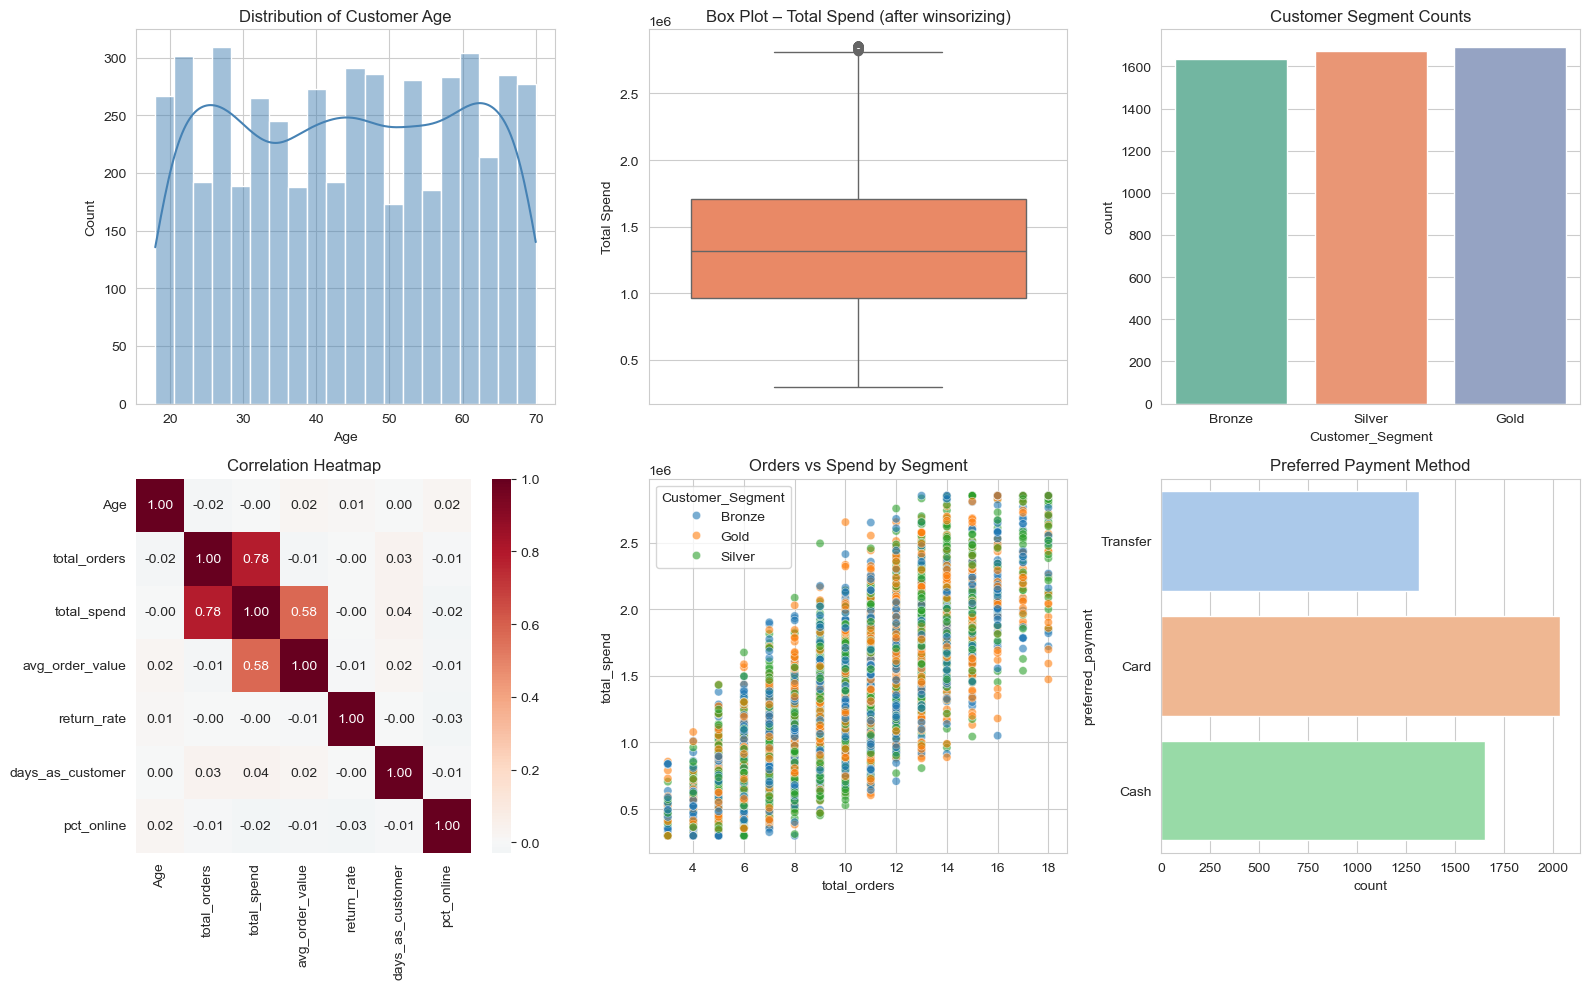

Figure saved: preprocessing_visualizations.png


In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# 1. Histogram – Age
sns.histplot(df_engineered['Age'], bins=20, kde=True, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Distribution of Customer Age')
axes[0,0].set_xlabel('Age')

# 2. Box plot – total_spend
sns.boxplot(y=df_engineered['total_spend'], ax=axes[0,1], color='coral')
axes[0,1].set_title('Box Plot – Total Spend (after winsorizing)')
axes[0,1].set_ylabel('Total Spend')

# 3. Count plot – Customer Segment
sns.countplot(x='Customer_Segment', data=df_engineered, order=['Bronze','Silver','Gold'],
              ax=axes[0,2], palette='Set2')
axes[0,2].set_title('Customer Segment Counts')

# 4. Correlation heatmap
corr_cols = ['Age','total_orders','total_spend','avg_order_value','return_rate','days_as_customer','pct_online']
corr = df_engineered[corr_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[1,0])
axes[1,0].set_title('Correlation Heatmap')

# 5. Scatter – total_orders vs total_spend
sns.scatterplot(x='total_orders', y='total_spend', hue='Customer_Segment',
                data=df_engineered, ax=axes[1,1], alpha=0.6)
axes[1,1].set_title('Orders vs Spend by Segment')

# 6. Count plot – preferred payment
sns.countplot(y='preferred_payment', data=df_engineered, ax=axes[1,2], palette='pastel')
axes[1,2].set_title('Preferred Payment Method')

plt.tight_layout()
plt.savefig('preprocessing_visualizations.png', dpi=120, bbox_inches='tight')
plt.show()
print("Figure saved: preprocessing_visualizations.png")

### Feature Selection
1. **Variance Threshold** – remove near-zero variance features.
2. **Correlation analysis** – drop highly collinear features (|r| > 0.85).

In [14]:
# Work on the scaled model matrix (exclude Customer_ID)
X = df_scaled.drop(columns=['Customer_ID'])

# 1. Variance Threshold
vt = VarianceThreshold(threshold=0.01)
vt.fit(X)
keep_mask = vt.get_support()
low_var_cols = X.columns[~keep_mask].tolist()
print("Low-variance columns removed:", low_var_cols)
X_var = X.loc[:, keep_mask]

# 2. Correlation filter
corr_matrix = X_var.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.85)]
print("Highly correlated columns dropped:", to_drop)
X_final = X_var.drop(columns=to_drop)

print("\nFinal feature matrix shape:", X_final.shape)
print("Final features:", X_final.columns.tolist())

Low-variance columns removed: []
Highly correlated columns dropped: ['total_quantity', 'total_spend', 'unique_products', 'unique_stores', 'return_rate']

Final feature matrix shape: (5000, 26)
Final features: ['Age', 'total_orders', 'avg_order_value', 'avg_discount', 'avg_shipping', 'pct_online', 'pct_completed', 'return_count', 'days_as_customer', 'Customer_Segment_ord', 'Gender_Male', 'State_Anambra', 'State_Delta', 'State_Enugu', 'State_Kaduna', 'State_Kano', 'State_Lagos', 'State_Ogun', 'State_Oyo', 'State_Rivers', 'preferred_payment_Cash', 'preferred_payment_Transfer', 'most_bought_category_Electronics', 'most_bought_category_Fashion', 'most_bought_category_Groceries', 'most_bought_category_Home']


## 7. Part 6 – Machine-Learning-Ready Dataset

The final dataset contains:
- Customer_ID (identifier)
- Scaled numeric behavioural features
- Encoded categorical features
- Target-ready `Customer_Segment_ord` (0=Bronze, 1=Silver, 2=Gold)

It is free of missing values, duplicates, and extreme outliers, and is ready for model training.

In [15]:
# Reconstruct final DataFrame
final_df = pd.concat([df_scaled[['Customer_ID']], X_final], axis=1)

# Also keep the human-readable segment label
final_df['Customer_Segment'] = df_engineered['Customer_Segment'].values

# Save
final_df.to_csv('ShopSmart_ML_Ready_Customers.csv', index=False)
print("Processed dataset saved: ShopSmart_ML_Ready_Customers.csv")
print("Shape:", final_df.shape)
display(final_df.head())
print("\nNull check (should be 0):", final_df.isnull().sum().sum())

Processed dataset saved: ShopSmart_ML_Ready_Customers.csv
Shape: (5000, 28)


,Customer_ID,Age,total_orders,avg_order_value,avg_discount,avg_shipping,pct_online,pct_completed,return_count,days_as_customer,Customer_Segment_ord,Gender_Male,State_Anambra,State_Delta,State_Enugu,State_Kaduna,State_Kano,State_Lagos,State_Ogun,State_Oyo,State_Rivers,preferred_payment_Cash,preferred_payment_Transfer,most_bought_category_Electronics,most_bought_category_Fashion,most_bought_category_Groceries,most_bought_category_Home,Customer_Segment
0,CUST00001,0.750000,-1.00,0.455310,-0.263158,1.448736,-0.993817,1.035144,0.0,0.500,0.0,True,False,False,False,False,False,False,False,False,False,False,True,True,False,False,False,Bronze
1,CUST00002,0.750000,0.50,-0.651978,1.052632,0.472984,-0.001405,-0.500467,1.0,0.706,2.0,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,Gold
2,CUST00003,0.392857,-0.75,0.361867,1.578947,-0.467090,-0.426724,1.473891,1.0,0.150,0.0,True,False,True,False,False,False,False,False,False,False,False,True,False,True,False,False,Bronze
3,CUST00004,-0.464286,1.25,-0.364190,1.263158,-0.885150,-0.993817,0.830396,0.0,0.596,2.0,True,False,False,False,False,False,True,False,False,False,True,False,False,False,True,False,Gold
4,CUST00005,0.321429,0.25,0.043643,-0.143541,-0.439384,-0.272063,0.197538,0.0,0.570,2.0,True,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,Gold



Null check (should be 0): 0


## 8. Summary of All Preprocessing Decisions

| Step | Action | Justification |
|------|--------|---------------|
| Missing values | None present | No imputation needed |
| Duplicates | None found | No removal |
| Data types | Dates → datetime, numerics validated | Correct for aggregation & tenure |
| PII / high-card. | Dropped names, email, phone, City | Privacy + dimensionality |
| Feature engineering | 14 behavioural features (RFM + returns + channel) | Capture purchase patterns for ML |
| Encoding | Ordinal (Segment), One-Hot (Gender, State, Payment, Category) | Preserve order / avoid ordinal assumption on nominals |
| Scaling | RobustScaler (counts/money), StandardScaler (ratios) | Outlier-resistant + distribution-aware |
| Outliers | IQR + Z-score detection; winsorize at 1%/99% | Retain all customers while limiting leverage |
| Feature selection | VarianceThreshold + correlation filter (|r|>0.85) | Reduce noise & multicollinearity |

### Answers to Business Questions
1. **Data quality issues** – Essentially clean; minor Gender label noise; future-dated transactions (simulated).
2. **Features requiring preprocessing** – Dates, categoricals, monetary columns, high-cardinality City.
3. **Encoding** – Ordinal for ordered Segment; One-Hot for nominals.
4. **Scaling** – RobustScaler + StandardScaler combination.
5. **Outliers** – Present in spend & order counts; treated by winsorization.
6. **Most useful features** – total_spend, total_orders, avg_order_value, return_rate, days_as_customer, pct_online.
7. **Ready for training?** – Yes. Saved as `ShopSmart_ML_Ready_Customers.csv`.

---
**End of Week 2 Notebook**  
All required sections (Inspection, Cleaning, Feature Engineering, Encoding & Scaling, Outlier Detection, Feature Selection, Final Dataset) and ≥6 visualizations are included.